# 03 · Two models: selection, tuning, calibration, evaluation

1. **Leakage analysis** — which columns cannot be used
2. For each model: compare 5 algorithms with 5-fold CV → tune the top two (Optuna) → simplest within 0.002 ROC-AUC wins → sigmoid calibration → business threshold → one evaluation on the untouched test set.

XGBoost trains on the **RTX 4060 GPU**. Every run is logged to **MLflow**.

In [1]:
%matplotlib inline
import warnings, os
warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from churnpulse import config
from churnpulse.dataset import load_customers
from churnpulse.features import FEATURE_CATEGORY, CATEGORIES
sns.set_theme(style="whitegrid", palette=["#0aa38a", "#f43f5e", "#f59e0b", "#6366f1", "#38bdf8"])
CAT_COLORS = {"geographic": "#38bdf8", "demographic": "#a78bfa", "technographic": "#22d3ee",
              "behavioural": "#fbbf24", "psychographic": "#f472b6"}
pd.set_option("display.max_columns", 50)


## 1 · Leakage analysis

In [2]:
pd.crosstab(load_customers().satisfaction_score, load_customers().churned, margins=True)

churned,0,1,All
satisfaction_score,,,
1,0,922,922
2,0,518,518
3,2236,429,2665
4,1789,0,1789
5,1149,0,1149
All,5174,1869,7043


**Every** customer with satisfaction 1–2 churned and **none** with 4–5 did. In this dataset the survey is almost a copy of the answer. Real surveys are weaker, so:

* the **profile model** (no survey) is the dependable baseline and scores new members;
* the **survey model** uses it when available — its accuracy is reported, with this caveat.

Columns known only *after* a customer leaves are always excluded:

In [3]:
from churnpulse.dataset import LEAKY_COLUMNS
LEAKY_COLUMNS

['Churn Score',
 'Churn Category',
 'Churn Reason',
 'Customer Status',
 'Churn Label',
 'Churn Value',
 'Count',
 'Quarter',
 'CLTV']

## 2 · Train both models

In [4]:
import logging
logging.basicConfig(level=logging.INFO, format='%(message)s')
from churnpulse import train as T
T.quiet_warnings()
split, results = T.train(n_trials=30)

== profile model (42 features)


  logistic_regression  roc_auc=0.8977 accuracy=0.8403


  random_forest        roc_auc=0.8962 accuracy=0.8466


  xgboost              roc_auc=0.9090 accuracy=0.8534


  lightgbm             roc_auc=0.9102 accuracy=0.8539


...

  xgboost              roc_auc=0.9926 accuracy=0.9615


  lightgbm             roc_auc=0.9929 accuracy=0.9633


  catboost             roc_auc=0.9930 accuracy=0.9647


  chosen: lightgbm (cv roc_auc 0.9933)


  test roc_auc=0.9927 accuracy=0.9652 (threshold 0.24)


In [5]:
for r in results:
    print(f'\n=== {r.kind} model ===')
    display(r.comparison.round(4))


=== profile model ===


,model,roc_auc,roc_auc_std,pr_auc,accuracy,f1,recall,precision,seconds
0,catboost,0.9119,0.0081,0.8012,0.8555,0.7091,0.6635,0.7618,2.4183
1,lightgbm,0.9102,0.0093,0.7952,0.8539,0.7112,0.6776,0.7486,0.8344
2,xgboost,0.9090,0.0096,0.7943,0.8534,0.7100,0.6763,0.7479,1.7670
3,logistic_regression,0.8977,0.0049,0.7694,0.8403,0.6871,0.6609,0.7159,0.5658
4,random_forest,0.8962,0.0057,0.7706,0.8466,0.6830,0.6227,0.7569,2.0658



=== survey model ===


,model,roc_auc,roc_auc_std,pr_auc,accuracy,f1,recall,precision,seconds
0,catboost,0.9930,0.0017,0.9842,0.9647,0.9314,0.9043,0.9605,2.3633
1,lightgbm,0.9929,0.0019,0.9840,0.9633,0.9291,0.9077,0.9519,0.8919
2,xgboost,0.9926,0.0020,0.9833,0.9615,0.9258,0.9050,0.9478,1.4839
3,logistic_regression,0.9923,0.0020,0.9825,0.9601,0.9237,0.9104,0.9378,0.4371
4,random_forest,0.9818,0.0059,0.9708,0.9636,0.9279,0.8843,0.9764,1.8994


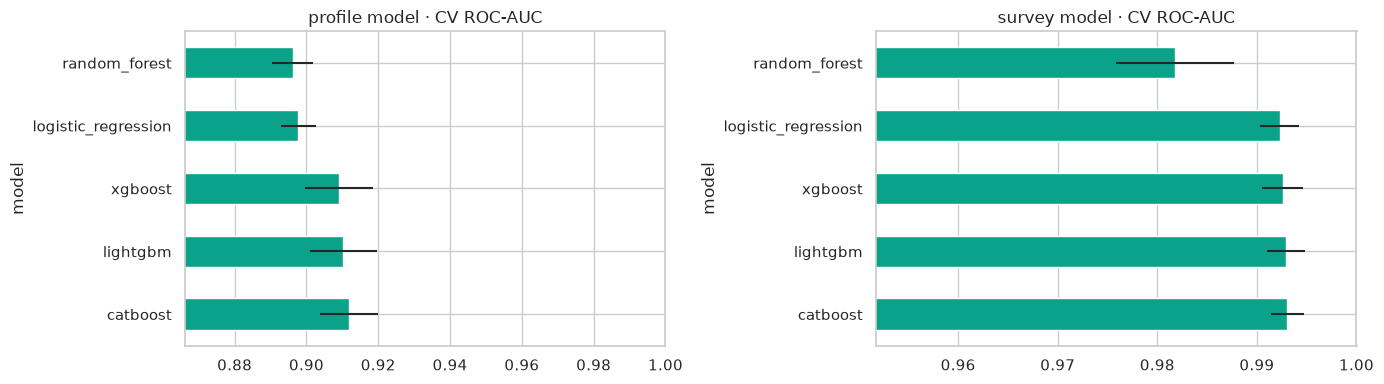

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, r in zip(axes, results):
    r.comparison.plot.barh(x='model', y='roc_auc', xerr='roc_auc_std', legend=False, ax=ax, color='#0aa38a')
    ax.set_xlim(r.comparison.roc_auc.min() - 0.03, 1); ax.set_title(f'{r.kind} model · CV ROC-AUC')
plt.tight_layout(); plt.show()

## 3 · Held-out test results

In [7]:
pd.DataFrame({r.kind: {k: v for k, v in r.test_metrics.items() if not isinstance(v, dict)} for r in results}).round(4)

,profile,survey
roc_auc,0.9166,0.9927
pr_auc,0.8038,0.9837
brier,0.1034,0.0270
threshold,0.4400,0.2400
accuracy,0.8573,0.9638
precision,0.7522,0.9330
recall,0.6898,0.9305
f1,0.7197,0.9317
accuracy_at_0.5,0.8545,0.9652
retention_value,32902.5150,53013.3450


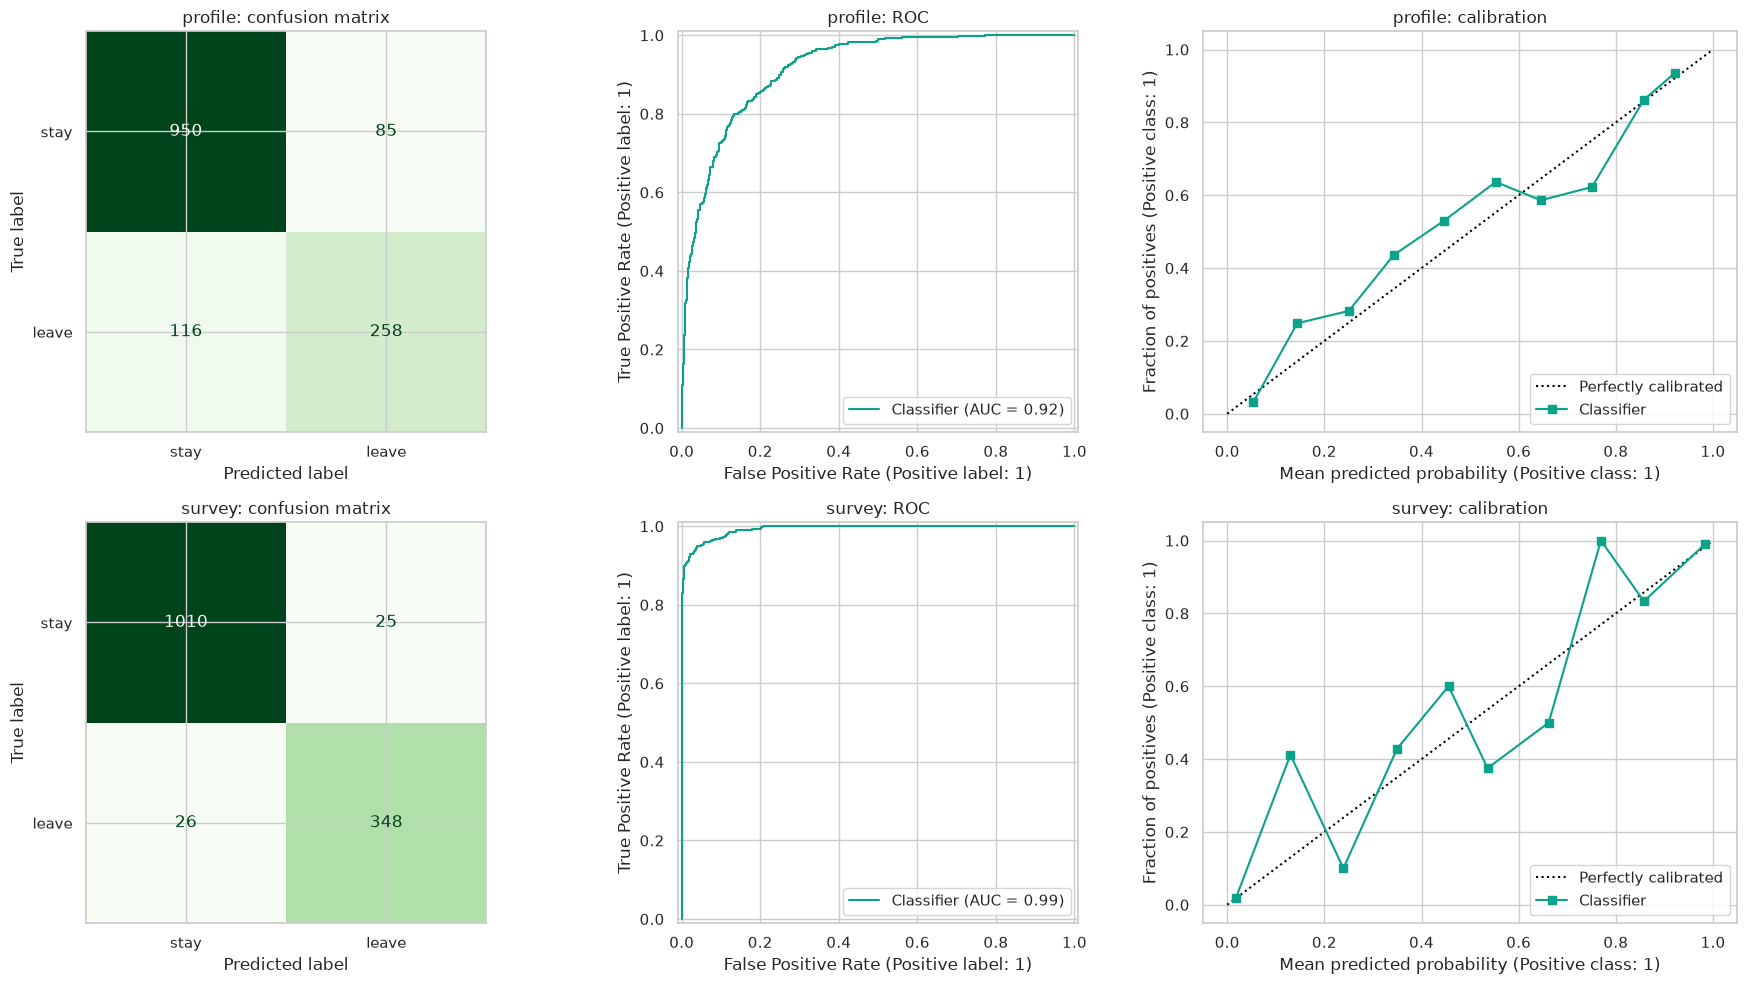

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.calibration import CalibrationDisplay
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for row, r in zip(axes, results):
    ConfusionMatrixDisplay.from_predictions(split.y_test, (r.test_proba >= r.threshold).astype(int), display_labels=['stay', 'leave'], ax=row[0], colorbar=False, cmap='Greens')
    RocCurveDisplay.from_predictions(split.y_test, r.test_proba, ax=row[1])
    CalibrationDisplay.from_predictions(split.y_test, r.test_proba, n_bins=10, ax=row[2])
    for ax, t in zip(row, ['confusion matrix', 'ROC', 'calibration']): ax.set_title(f'{r.kind}: {t}')
plt.tight_layout(); plt.show()

In [9]:
for r in results:
    m = r.test_metrics
    print(f"{r.kind:8s} {r.best.name:12s} accuracy {m['accuracy_at_0.5']:.1%}  ROC-AUC {m['roc_auc']:.3f}  "
          f"saves ${m['retention_value']:,.0f} vs ${m['retention_value_contact_everyone']:,.0f} contacting everyone")

profile  lightgbm     accuracy 85.5%  ROC-AUC 0.917  saves $32,903 vs $-35,529 contacting everyone
survey   lightgbm     accuracy 96.5%  ROC-AUC 0.993  saves $53,013 vs $-35,529 contacting everyone


## 4 · Export
`make train` (`python -m churnpulse.train`) runs exactly this code, exports both models and registers them in MLflow. Set `EXPORT = True` to export from here.

In [10]:
EXPORT = False
if EXPORT:
    T.export(split, results)